In [ ]:
!pip install -q pandas numpy scikit-learn imbalanced-learn joblib pyarrow matplotlib seaborn xgboost

In [ ]:
import pandas as pd
import numpy as np
import sklearn
import imblearn
import joblib
import pyarrow
import xgboost

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Imbalanced-learn:", imblearn.__version__)
print("Joblib:", joblib.__version__)
print("PyArrow:", pyarrow.__version__)
print("XGBoost:", xgboost.__version__)

print("\nAll libraries imported successfully!")

Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
Imbalanced-learn: 0.14.2
Joblib: 1.6.0
PyArrow: 23.0.1
XGBoost: 3.4.1

All libraries imported successfully!


In [ ]:
import time
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

CLASS_NAMES = [
    'Bots',
    'Brute Force',
    'DDoS',
    'DoS',
    'Normal Traffic',
    'Port Scanning',
    'Web Attacks'
]

NORMAL_ID = CLASS_NAMES.index('Normal Traffic')

results = []

print("Model evaluation setup is ready!")
print("Number of classes:", len(CLASS_NAMES))
print("Normal Traffic class ID:", NORMAL_ID)

Model evaluation setup is ready!
Number of classes: 7
Normal Traffic class ID: 4


In [ ]:
def evaluate_model(name, model, X, y, training_time):
    start = time.time()
    predictions = model.predict(X)
    prediction_time = time.time() - start

    macro_f1 = f1_score(y, predictions, average='macro')
    macro_recall = recall_score(y, predictions, average='macro')
    macro_precision = precision_score(y, predictions, average='macro')

    normal_mask = (y == NORMAL_ID)
    false_positive_rate = np.sum(
        (predictions != NORMAL_ID) & normal_mask
    ) / np.sum(normal_mask)

    attack_mask = (y != NORMAL_ID)
    attack_recall = np.sum(
        (predictions != NORMAL_ID) & attack_mask
    ) / np.sum(attack_mask)

    record = {
        'model': name,
        'macro_f1': macro_f1,
        'macro_recall': macro_recall,
        'macro_precision': macro_precision,
        'attack_recall': attack_recall,
        'false_positive_rate': false_positive_rate,
        'training_seconds': training_time,
        'prediction_ms_per_record': (
            prediction_time / len(X)
        ) * 1000
    }

    results.append(record)

    print(f"\n{name} Evaluation")
    print(classification_report(
        y, predictions,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y, predictions,
        labels=list(range(len(CLASS_NAMES)))
    ))

    return record


print("Evaluation function is ready!")

Evaluation function is ready!


In [ ]:
from sklearn.model_selection import train_test_split

# Generate fake data: 40,000 rows and 46 features
X_fake = np.random.rand(40000, 46).astype('float32')

# Generate seven fake classes
y_fake = np.random.randint(0, 7, 40000)

# Split into practice training and validation sets
X_train_fake, X_val_fake, y_train_fake, y_val_fake = train_test_split(
    X_fake,
    y_fake,
    test_size=0.25,
    random_state=42
)

print("Practice dataset created!")
print("Training shape:", X_train_fake.shape)
print("Validation shape:", X_val_fake.shape)
print("Number of features:", X_train_fake.shape[1])

Practice dataset created!
Training shape: (30000, 46)
Validation shape: (10000, 46)
Number of features: 46


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE = '/content/drive/MyDrive/Kalasag-data/processed'
SAVE = '/content/drive/MyDrive/Kalasag-models'

os.makedirs(SAVE, exist_ok=True)

print("Dataset folder exists:", os.path.exists(BASE))
print("Model folder exists:", os.path.exists(SAVE))

Dataset folder exists: False
Model folder exists: True


In [ ]:
from sklearn.tree import DecisionTreeClassifier
import time

tree = DecisionTreeClassifier(
    max_depth=25,
    random_state=42
)

start = time.time()

tree.fit(X_train_fake, y_train_fake)

training_time = time.time() - start

print("Decision Tree training completed!")
print("Training time:", round(training_time, 2), "seconds")

NameError: name 'X_train_fake' is not defined

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# Generate fake data
X_fake = np.random.rand(40000, 46).astype('float32')
y_fake = np.random.randint(0, 7, 40000)

# Split into training and validation
X_train_fake, X_val_fake, y_train_fake, y_val_fake = train_test_split(
    X_fake,
    y_fake,
    test_size=0.25,
    random_state=42
)

print("Practice dataset recreated!")
print("Training:", X_train_fake.shape)
print("Validation:", X_val_fake.shape)

Practice dataset recreated!
Training: (30000, 46)
Validation: (10000, 46)


In [ ]:
from sklearn.tree import DecisionTreeClassifier
import time

tree = DecisionTreeClassifier(
    max_depth=25,
    random_state=42
)

start = time.time()
tree.fit(X_train_fake, y_train_fake)
training_time = time.time() - start

print("Decision Tree training completed!")
print("Training time:", round(training_time, 2), "seconds")

Decision Tree training completed!
Training time: 6.71 seconds


In [ ]:
evaluate_model(
    "Practice Decision Tree",
    tree,
    X_val_fake,
    y_val_fake,
    training_time
)

NameError: name 'evaluate_model' is not defined

In [ ]:
import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

CLASS_NAMES = [
    'Bots',
    'Brute Force',
    'DDoS',
    'DoS',
    'Normal Traffic',
    'Port Scanning',
    'Web Attacks'
]

NORMAL_ID = CLASS_NAMES.index('Normal Traffic')

results = []

def evaluate_model(name, model, X, y, training_time):
    start = time.time()
    predictions = model.predict(X)
    prediction_time = time.time() - start

    macro_f1 = f1_score(y, predictions, average='macro')
    macro_recall = recall_score(y, predictions, average='macro')
    macro_precision = precision_score(y, predictions, average='macro')

    normal_mask = (y == NORMAL_ID)
    false_positive_rate = np.sum(
        (predictions != NORMAL_ID) & normal_mask
    ) / np.sum(normal_mask)

    attack_mask = (y != NORMAL_ID)
    attack_recall = np.sum(
        (predictions != NORMAL_ID) & attack_mask
    ) / np.sum(attack_mask)

    record = {
        'model': name,
        'macro_f1': macro_f1,
        'macro_recall': macro_recall,
        'macro_precision': macro_precision,
        'attack_recall': attack_recall,
        'false_positive_rate': false_positive_rate,
        'training_seconds': training_time,
        'prediction_ms_per_record': (
            prediction_time / len(X)
        ) * 1000
    }

    results.append(record)

    print(f"\n{name} Evaluation")

    print(classification_report(
        y,
        predictions,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y,
        predictions,
        labels=list(range(len(CLASS_NAMES)))
    ))

    return record

print("Evaluation function restored!")

Evaluation function restored!


In [ ]:
evaluate_model(
    "Practice Decision Tree",
    tree,
    X_val_fake,
    y_val_fake,
    training_time
)


Practice Decision Tree Evaluation
                precision    recall  f1-score   support

          Bots       0.15      0.14      0.14      1474
   Brute Force       0.14      0.15      0.15      1405
          DDoS       0.13      0.16      0.14      1412
           DoS       0.13      0.09      0.11      1416
Normal Traffic       0.16      0.11      0.13      1444
 Port Scanning       0.15      0.18      0.16      1435
   Web Attacks       0.13      0.14      0.14      1414

      accuracy                           0.14     10000
     macro avg       0.14      0.14      0.14     10000
  weighted avg       0.14      0.14      0.14     10000

Confusion Matrix:
[[209 212 251 162 150 258 232]
 [210 216 253 130 132 242 222]
 [206 200 226 139 149 261 231]
 [206 202 259 131 144 253 221]
 [200 229 234 156 165 240 220]
 [189 222 265 145 135 264 215]
 [191 212 262 142 150 254 203]]


{'model': 'Practice Decision Tree',
 'macro_f1': 0.14009643146659712,
 'macro_recall': 0.14141441299242774,
 'macro_precision': 0.1419606654648973,
 'attack_recall': np.float64(0.8994857410004675),
 'false_positive_rate': np.float64(0.8857340720221607),
 'training_seconds': 6.706521272659302,
 'prediction_ms_per_record': 0.0007106304168701172}

In [ ]:
import joblib
import os

SAVE = '/content/drive/MyDrive/Kalasag-models'
os.makedirs(SAVE, exist_ok=True)

joblib.dump(tree, f'{SAVE}/practice_tree.joblib')

print("Practice model saved successfully!")
print("Location:", f'{SAVE}/practice_tree.joblib')

Practice model saved successfully!
Location: /content/drive/MyDrive/Kalasag-models/practice_tree.joblib


In [ ]:
# Clear practice evaluation results
results.clear()

# Remove fake training data from memory
del X_fake, y_fake
del X_train_fake, X_val_fake
del y_train_fake, y_val_fake

# Remove the practice model from memory
del tree

print("Practice data and results cleared!")
print("Results list:", results)

Practice data and results cleared!
Results list: []


In [1]:
import os

print("My Drive folders:")
print(os.listdir('/content/drive/MyDrive'))

My Drive folders:


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive'

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'received_2303667026616590.mp4', '2021-05-28 01-43-57.mp4', '2021-06-07 15-22-14_Trim.mp4', '2021-06-07 19-04-08_Trim.mp4', '2021-12-21 14-52-30.mkv', 'ROBLOX MAMA MO.mp4', '2022-11-17 00-54-54 (1).mkv', 'ALI&MACDON_DRRR.mp4', 'Ali, Jasmine', 'okay.mp4', '2022-11-17 00-54-54.mkv', 'roblox', '25. PROGRAMMING CODING ULTIMATE COURSE', 'gta5 shot.mp4', 'KASAL NI JAZE AT TECO', 'KASAL NI LAI AT SATORU', 'KASAL NI ANTON AT REKO', 'ROBLOX', '2x2.jpg', 'CS1A-PathFit-Format (2).docx', 'CS1A-PathFit-Format (1).docx', 'CS1A-PathFit-Format.docx', 'Botb', '4ATIS_WEEKNO.1.gdoc', 'muwah - Made with Clipchamp.mp4', 'Reflexes - Made with Clipchamp.mp4', 'mowah.mp4', 'REPO CLIPS', 'forest', 'Screenshot 2025-07-08 004505 (1).png', 'Screenshot 2025-07-08 004933 (1).png', 'Screenshot 2025-07-08 004556 (1).png', 'Screenshot 2025-07-08 004943 (1).png', 'Screenshot 2025-07-08 004951 (1).png', 'Screenshot 2025-07-08 005043 (1).png', 'Screenshot 2025-07-08 005513 (1).png', 'Screenshot 2025-0

In [4]:
import os

BASE = '/content/drive/MyDrive/processed'

print("Files inside processed folder:")
for file in os.listdir(BASE):
    print(file)

Files inside processed folder:
split_test_unscaled.parquet
scaler.pkl
scaler.json
train_scaled.parquet
train_smote_floor10000.parquet
val_scaled.parquet
test_scaled.parquet


In [5]:
import pandas as pd
import numpy as np
import os

BASE = '/content/drive/MyDrive/processed'
SAVE = '/content/drive/MyDrive/Kalasag-models'

os.makedirs(SAVE, exist_ok=True)

# Load training and validation data only
train_sm = pd.read_parquet(f'{BASE}/train_smote_floor10000.parquet')
val = pd.read_parquet(f'{BASE}/val_scaled.parquet')

# Separate features and labels
X_train = train_sm.drop(columns='label').astype('float32')
y_train = train_sm['label'].astype('int64')

X_val = val.drop(columns='label').astype('float32')
y_val = val['label'].astype('int64')

# Display dataset information
print("TRAINING DATA")
print("Rows:", X_train.shape[0])
print("Features:", X_train.shape[1])

print("\nVALIDATION DATA")
print("Rows:", X_val.shape[0])
print("Features:", X_val.shape[1])

print("\nTraining label counts:")
print(y_train.value_counts().sort_index())

print("\nValidation label counts:")
print(y_val.value_counts().sort_index())

TRAINING DATA
Rows: 1783111
Features: 46

VALIDATION DATA
Rows: 377652
Features: 46

Training label counts:
label
0      10000
1      10000
2      89596
3     135507
4    1464522
5      63486
6      10000
Name: count, dtype: int64

Validation label counts:
label
0       292
1      1372
2     19199
3     29037
4    313826
5     13604
6       322
Name: count, dtype: int64


In [6]:
import time
import joblib
import numpy as np

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score,
    classification_report,
    confusion_matrix
)

# Create and train the model
tree = DecisionTreeClassifier(
    max_depth=25,
    random_state=42
)

print("Training Decision Tree...")
start_time = time.time()

tree.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds.")

# Save the trained model immediately
model_path = f'{SAVE}/decision_tree.joblib'
joblib.dump(tree, model_path)

print(f"Model saved to: {model_path}")

# Evaluate using validation data
start_time = time.time()
predictions = tree.predict(X_val)
prediction_time = time.time() - start_time

NORMAL_ID = 4

attack_mask = (y_val != NORMAL_ID)
normal_mask = (y_val == NORMAL_ID)

attack_recall = np.sum(
    (predictions != NORMAL_ID) & attack_mask
) / np.sum(attack_mask)

false_positive_rate = np.sum(
    (predictions != NORMAL_ID) & normal_mask
) / np.sum(normal_mask)

print("\nDECISION TREE RESULTS")
print("Macro F1:", round(f1_score(y_val, predictions, average='macro'), 4))
print("Macro Recall:", round(recall_score(y_val, predictions, average='macro'), 4))
print("Macro Precision:", round(precision_score(y_val, predictions, average='macro'), 4))
print("Attack Recall:", round(attack_recall, 4))
print("False Positive Rate:", round(false_positive_rate, 4))
print("Training Time:", round(training_time, 2), "seconds")
print("Prediction Latency:", round((prediction_time / len(X_val)) * 1000, 4), "ms/record")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    predictions,
    target_names=CLASS_NAMES,
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val, predictions))

Training Decision Tree...
Training completed in 108.58 seconds.
Model saved to: /content/drive/MyDrive/Kalasag-models/decision_tree.joblib

DECISION TREE RESULTS
Macro F1: 0.9648
Macro Recall: 0.9737
Macro Precision: 0.9572
Attack Recall: 0.9966
False Positive Rate: 0.0009
Training Time: 108.58 seconds
Prediction Latency: 0.0003 ms/record

CLASSIFICATION REPORT


NameError: name 'CLASS_NAMES' is not defined

In [7]:
CLASS_NAMES = [
    'Bots',
    'Brute Force',
    'DDoS',
    'DoS',
    'Normal Traffic',
    'Port Scanning',
    'Web Attacks'
]

from sklearn.metrics import classification_report, confusion_matrix

print("CLASSIFICATION REPORT")
print(classification_report(
    y_val,
    predictions,
    target_names=CLASS_NAMES,
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val, predictions))

CLASSIFICATION REPORT
                precision    recall  f1-score   support

          Bots       0.73      0.85      0.79       292
   Brute Force       1.00      1.00      1.00      1372
          DDoS       1.00      1.00      1.00     19199
           DoS       1.00      1.00      1.00     29037
Normal Traffic       1.00      1.00      1.00    313826
 Port Scanning       0.99      0.99      0.99     13604
   Web Attacks       0.98      0.98      0.98       322

      accuracy                           1.00    377652
     macro avg       0.96      0.97      0.96    377652
  weighted avg       1.00      1.00      1.00    377652


CONFUSION MATRIX
[[   249      0      0      0     43      0      0]
 [     0   1369      0      1      2      0      0]
 [     0      0  19192      0      7      0      0]
 [     0      0      0  28999     30      6      2]
 [    92      1      4     52 313538    136      3]
 [     0      0      0      6    131  13467      0]
 [     0      0      0      2

In [8]:
import time
import joblib
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score,
    classification_report,
    confusion_matrix
)

lr = LogisticRegression(
    max_iter=100,
    random_state=42
)

print("Training Logistic Regression...")
start_time = time.time()

lr.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds.")

# Save immediately
model_path = f'{SAVE}/logistic_regression.joblib'
joblib.dump(lr, model_path)

print(f"Model saved to: {model_path}")

# Validation
start_time = time.time()
lr_predictions = lr.predict(X_val)
prediction_time = time.time() - start_time

NORMAL_ID = 4
attack_mask = (y_val != NORMAL_ID)
normal_mask = (y_val == NORMAL_ID)

attack_recall = np.sum(
    (lr_predictions != NORMAL_ID) & attack_mask
) / np.sum(attack_mask)

false_positive_rate = np.sum(
    (lr_predictions != NORMAL_ID) & normal_mask
) / np.sum(normal_mask)

print("\nLOGISTIC REGRESSION RESULTS")
print("Macro F1:", round(f1_score(y_val, lr_predictions, average='macro'), 4))
print("Macro Recall:", round(recall_score(y_val, lr_predictions, average='macro'), 4))
print("Macro Precision:", round(precision_score(y_val, lr_predictions, average='macro'), 4))
print("Attack Recall:", round(attack_recall, 4))
print("False Positive Rate:", round(false_positive_rate, 4))
print("Training Time:", round(training_time, 2), "seconds")
print("Prediction Latency:", round((prediction_time / len(X_val)) * 1000, 4), "ms/record")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    lr_predictions,
    target_names=CLASS_NAMES,
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val, lr_predictions))

Training Logistic Regression...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training completed in 104.49 seconds.
Model saved to: /content/drive/MyDrive/Kalasag-models/logistic_regression.joblib

LOGISTIC REGRESSION RESULTS
Macro F1: 0.6863
Macro Recall: 0.6901
Macro Precision: 0.6977
Attack Recall: 0.9479
False Positive Rate: 0.0162
Training Time: 104.49 seconds
Prediction Latency: 0.0004 ms/record

CLASSIFICATION REPORT
                precision    recall  f1-score   support

          Bots       0.11      0.02      0.03       292
   Brute Force       0.81      0.76      0.78      1372
          DDoS       1.00      1.00      1.00     19199
           DoS       0.99      0.93      0.96     29037
Normal Traffic       0.99      0.98      0.99    313826
 Port Scanning       0.75      0.97      0.85     13604
   Web Attacks       0.24      0.18      0.20       322

      accuracy                           0.98    377652
     macro avg       0.70      0.69      0.69    377652
  weighted avg       0.98      0.98      0.98    377652


CONFUSION MATRIX
[[     5     

In [9]:
import time
import joblib
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score,
    classification_report,
    confusion_matrix
)

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=25,
    max_samples=0.5,
    n_jobs=-1,
    random_state=42
)

print("Training Random Forest...")
start_time = time.time()

rf.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds.")

# Save immediately
model_path = f'{SAVE}/random_forest.joblib'
joblib.dump(rf, model_path)

print(f"Model saved to: {model_path}")

# Evaluate using validation data
start_time = time.time()
rf_predictions = rf.predict(X_val)
prediction_time = time.time() - start_time

NORMAL_ID = 4
attack_mask = (y_val != NORMAL_ID)
normal_mask = (y_val == NORMAL_ID)

attack_recall = np.sum(
    (rf_predictions != NORMAL_ID) & attack_mask
) / np.sum(attack_mask)

false_positive_rate = np.sum(
    (rf_predictions != NORMAL_ID) & normal_mask
) / np.sum(normal_mask)

print("\nRANDOM FOREST RESULTS")
print("Macro F1:", round(f1_score(y_val, rf_predictions, average='macro'), 4))
print("Macro Recall:", round(recall_score(y_val, rf_predictions, average='macro'), 4))
print("Macro Precision:", round(precision_score(y_val, rf_predictions, average='macro'), 4))
print("Attack Recall:", round(attack_recall, 4))
print("False Positive Rate:", round(false_positive_rate, 4))
print("Training Time:", round(training_time, 2), "seconds")
print("Prediction Latency:", round((prediction_time / len(X_val)) * 1000, 4), "ms/record")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    rf_predictions,
    target_names=CLASS_NAMES,
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val, rf_predictions))

Training Random Forest...
Training completed in 369.70 seconds.
Model saved to: /content/drive/MyDrive/Kalasag-models/random_forest.joblib

RANDOM FOREST RESULTS
Macro F1: 0.9674
Macro Recall: 0.9797
Macro Precision: 0.9574
Attack Recall: 0.9976
False Positive Rate: 0.0009
Training Time: 369.7 seconds
Prediction Latency: 0.0118 ms/record

CLASSIFICATION REPORT
                precision    recall  f1-score   support

          Bots       0.73      0.89      0.80       292
   Brute Force       1.00      1.00      1.00      1372
          DDoS       1.00      1.00      1.00     19199
           DoS       1.00      1.00      1.00     29037
Normal Traffic       1.00      1.00      1.00    313826
 Port Scanning       0.99      1.00      0.99     13604
   Web Attacks       0.99      0.98      0.98       322

      accuracy                           1.00    377652
     macro avg       0.96      0.98      0.97    377652
  weighted avg       1.00      1.00      1.00    377652


CONFUSION MATRIX


In [10]:
!nvidia-smi

Sun Nov  8 15:14:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [11]:
import time
import joblib
import numpy as np

from xgboost import XGBClassifier
from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score,
    classification_report,
    confusion_matrix
)

# Create XGBoost model
xgb = XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.2,
    tree_method='hist',
    device='cuda',
    objective='multi:softprob',
    random_state=42
)

print("Training XGBoost using Tesla T4 GPU...")
start_time = time.time()

xgb.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds.")

# Save immediately
model_path = f'{SAVE}/xgboost.joblib'
joblib.dump(xgb, model_path)

print(f"Model saved to: {model_path}")

# Validation
start_time = time.time()
xgb_predictions = xgb.predict(X_val)
prediction_time = time.time() - start_time

NORMAL_ID = 4
attack_mask = (y_val != NORMAL_ID)
normal_mask = (y_val == NORMAL_ID)

attack_recall = np.sum(
    (xgb_predictions != NORMAL_ID) & attack_mask
) / np.sum(attack_mask)

false_positive_rate = np.sum(
    (xgb_predictions != NORMAL_ID) & normal_mask
) / np.sum(normal_mask)

print("\nXGBOOST RESULTS")
print("Macro F1:", round(f1_score(y_val, xgb_predictions, average='macro'), 4))
print("Macro Recall:", round(recall_score(y_val, xgb_predictions, average='macro'), 4))
print("Macro Precision:", round(precision_score(y_val, xgb_predictions, average='macro'), 4))
print("Attack Recall:", round(attack_recall, 4))
print("False Positive Rate:", round(false_positive_rate, 4))
print("Training Time:", round(training_time, 2), "seconds")
print("Prediction Latency:", round((prediction_time / len(X_val)) * 1000, 4), "ms/record")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    xgb_predictions,
    target_names=CLASS_NAMES,
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val, xgb_predictions))

Training XGBoost using Tesla T4 GPU...
Training completed in 37.65 seconds.
Model saved to: /content/drive/MyDrive/Kalasag-models/xgboost.joblib


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [15:15:51] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)



XGBOOST RESULTS
Macro F1: 0.9661
Macro Recall: 0.9809
Macro Precision: 0.9544
Attack Recall: 0.999
False Positive Rate: 0.0009
Training Time: 37.65 seconds
Prediction Latency: 0.0017 ms/record

CLASSIFICATION REPORT
                precision    recall  f1-score   support

          Bots       0.70      0.89      0.78       292
   Brute Force       1.00      1.00      1.00      1372
          DDoS       1.00      1.00      1.00     19199
           DoS       1.00      1.00      1.00     29037
Normal Traffic       1.00      1.00      1.00    313826
 Port Scanning       0.99      1.00      0.99     13604
   Web Attacks       0.99      0.98      0.99       322

      accuracy                           1.00    377652
     macro avg       0.95      0.98      0.97    377652
  weighted avg       1.00      1.00      1.00    377652


CONFUSION MATRIX
[[   259      0      0      0     33      0      0]
 [     0   1369      0      0      3      0      0]
 [     0      0  19196      0      3      

In [12]:
import pandas as pd
import numpy as np

# Load original training data, not SMOTE data
train_original = pd.read_parquet(
    f'{BASE}/train_scaled.parquet'
)

# Validation data is already loaded
feature_cols = [
    col for col in train_original.columns
    if col != 'label'
]

print("Original training shape:", train_original.shape)
print("Validation shape:", val.shape)

print("\nChecking duplicate records...")

# Hash feature values and labels
train_hash = pd.util.hash_pandas_object(
    train_original[feature_cols + ['label']],
    index=False
)

val_hash = pd.util.hash_pandas_object(
    val[feature_cols + ['label']],
    index=False
)

# Check exact matching records across splits
train_hash_set = set(train_hash.values)

overlap_count = sum(
    value in train_hash_set
    for value in val_hash.values
)

print("\nEXACT OVERLAP CHECK")
print("Matching training and validation records:", overlap_count)
print("Validation records:", len(val))
print(
    "Overlap percentage:",
    round((overlap_count / len(val)) * 100, 4),
    "%"
)

# Check duplicates within each dataset
print("\nDUPLICATE CHECK")
print(
    "Training duplicate rows:",
    train_original.duplicated().sum()
)
print(
    "Validation duplicate rows:",
    val.duplicated().sum()
)

Original training shape: (1762376, 47)
Validation shape: (377652, 47)

Checking duplicate records...

EXACT OVERLAP CHECK
Matching training and validation records: 3
Validation records: 377652
Overlap percentage: 0.0008 %

DUPLICATE CHECK
Training duplicate rows: 5
Validation duplicate rows: 0


In [13]:
import numpy as np
import pandas as pd

feature_cols = [
    col for col in train_original.columns
    if col != 'label'
]

# Hash features only, excluding labels
train_feature_hash = pd.util.hash_pandas_object(
    train_original[feature_cols],
    index=False
).to_numpy()

val_feature_hash = pd.util.hash_pandas_object(
    val[feature_cols],
    index=False
).to_numpy()

# Sort training hashes for efficient matching
sort_idx = np.argsort(train_feature_hash)
sorted_train_hash = train_feature_hash[sort_idx]

# Find matching feature records
positions = np.searchsorted(
    sorted_train_hash,
    val_feature_hash
)

valid = positions < len(sorted_train_hash)

matched = np.zeros(len(val_feature_hash), dtype=bool)

matched[valid] = (
    sorted_train_hash[positions[valid]]
    == val_feature_hash[valid]
)

# Compare labels for matching features
matched_val_indices = np.where(matched)[0]
matched_train_indices = sort_idx[positions[matched]]

train_labels = train_original['label'].to_numpy()
val_labels = val['label'].to_numpy()

conflicting_labels = np.sum(
    train_labels[matched_train_indices]
    != val_labels[matched_val_indices]
)

print("FEATURE-ONLY OVERLAP CHECK")
print("Matching feature records:", matched.sum())
print("Validation records:", len(val))
print(
    "Overlap percentage:",
    round(matched.mean() * 100, 4),
    "%"
)
print("Matching features with different labels:", conflicting_labels)

FEATURE-ONLY OVERLAP CHECK
Matching feature records: 144
Validation records: 377652
Overlap percentage: 0.0381 %
Matching features with different labels: 141


In [14]:
# Find records with identical features but different labels

train_features = train_original[feature_cols].copy()
val_features = val[feature_cols].copy()

# Create hashes using features only
train_feature_hash = pd.util.hash_pandas_object(
    train_features,
    index=False
)

val_feature_hash = pd.util.hash_pandas_object(
    val_features,
    index=False
)

# Map training feature hashes to their labels
train_hash_labels = pd.DataFrame({
    'feature_hash': train_feature_hash.values,
    'train_label': train_original['label'].values
})

val_hash_labels = pd.DataFrame({
    'feature_hash': val_feature_hash.values,
    'val_label': val['label'].values
})

# Find matching feature hashes
matches = val_hash_labels.merge(
    train_hash_labels,
    on='feature_hash',
    how='inner'
)

# Keep records with different labels
conflicts = matches[
    matches['val_label'] != matches['train_label']
]

print("CONFLICTING FEATURE RECORDS")
print("Total matches:", len(matches))
print("Different labels:", len(conflicts))

print("\nLABEL CONFLICT COMBINATIONS:")
print(
    conflicts.groupby(
        ['train_label', 'val_label']
    ).size().sort_values(ascending=False)
)

print("\nSAMPLE CONFLICTS:")
print(conflicts.head(20))

CONFLICTING FEATURE RECORDS
Total matches: 144
Different labels: 141

LABEL CONFLICT COMBINATIONS:
train_label  val_label
5            4            60
4            5            57
3            4            15
4            3             9
dtype: int64

SAMPLE CONFLICTS:
            feature_hash  val_label  train_label
0    9281883595869021074          4            5
1   11271599893752409964          5            4
2   13058460904738585337          4            5
3    7277643008388857716          4            3
4    2624333416581228767          4            3
5   11245845768798135365          4            5
6   10871764418015186607          4            3
7   16426980482257042762          5            4
8    9264749078474004464          5            4
9    5975415282677721219          4            5
10  18016197537798897378          5            4
11   5062234966289124801          5            4
12  13412595887480800629          5            4
13  12470382990154311612          4         

In [15]:
# Count unique conflicting feature records
print("Unique conflicting feature hashes:",
      conflicts['feature_hash'].nunique())

print("\nConflicting records by label combination:")
print(
    conflicts.groupby(
        ['train_label', 'val_label']
    )['feature_hash'].nunique()
)

print("\nRepeated feature hashes in original training:")
print(train_feature_hash.duplicated().sum())

print("\nRepeated feature hashes in validation:")
print(val_feature_hash.duplicated().sum())

Unique conflicting feature hashes: 141

Conflicting records by label combination:
train_label  val_label
3            4            15
4            3             9
             5            57
5            4            60
Name: feature_hash, dtype: int64

Repeated feature hashes in original training:
341

Repeated feature hashes in validation:
19


In [16]:
import joblib
import pandas as pd

# Load the saved models
rf_model = joblib.load(
    f'{SAVE}/random_forest.joblib'
)

xgb_model = joblib.load(
    f'{SAVE}/xgboost.joblib'
)

# Get the original 46 feature names
feature_names = X_train.columns

# Create feature importance tables
rf_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
)

xgb_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_model.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
)

print("RANDOM FOREST: TOP 15 FEATURES")
display(rf_importance.head(15))

print("XGBOOST: TOP 15 FEATURES")
display(xgb_importance.head(15))

RANDOM FOREST: TOP 15 FEATURES


,Feature,Importance
11,Bwd Packet Length Std,0.077218
35,Packet Length Std,0.072007
36,Packet Length Variance,0.070055
10,Bwd Packet Length Mean,0.059178
8,Bwd Packet Length Max,0.048635
3,Total Length of Fwd Packets,0.047881
40,Average Packet Size,0.039661
4,Fwd Packet Length Max,0.036436
34,Packet Length Mean,0.030415
33,Max Packet Length,0.029944


XGBOOST: TOP 15 FEATURES


,Feature,Importance
11,Bwd Packet Length Std,0.252803
44,act_data_pkt_fwd,0.085178
10,Bwd Packet Length Mean,0.071548
26,Bwd IAT Max,0.059070
40,Average Packet Size,0.050011
3,Total Length of Fwd Packets,0.047072
0,Destination Port,0.044373
13,Flow Packets/s,0.042445
12,Flow Bytes/s,0.037099
4,Fwd Packet Length Max,0.036802


In [17]:
import time
import numpy as np
import joblib

# Load all four trained models
models = {
    "Decision Tree": joblib.load(f'{SAVE}/decision_tree.joblib'),
    "Logistic Regression": joblib.load(f'{SAVE}/logistic_regression.joblib'),
    "Random Forest": joblib.load(f'{SAVE}/random_forest.joblib'),
    "XGBoost": joblib.load(f'{SAVE}/xgboost.joblib')
}

# Use 300 validation records only
X_benchmark = X_val.iloc[:300].copy()

results = []

for name, model in models.items():

    # Ensure XGBoost prediction uses CPU
    if name == "XGBoost":
        model.get_booster().set_param({"device": "cpu"})

    # Warm-up prediction
    model.predict(X_benchmark)

    timings = []

    # Repeat benchmark 10 times
    for _ in range(10):
        start = time.perf_counter()

        model.predict(X_benchmark)

        end = time.perf_counter()
        timings.append(end - start)

    median_time = np.median(timings)
    mean_time = np.mean(timings)

    results.append({
        "Model": name,
        "Median Total Time (ms)": median_time * 1000,
        "Mean Total Time (ms)": mean_time * 1000,
        "Median Latency (ms/record)": median_time * 1000 / 300
    })

latency_results = pd.DataFrame(results)

display(
    latency_results.sort_values(
        by="Median Latency (ms/record)"
    )
)

,Model,Median Total Time (ms),Mean Total Time (ms),Median Latency (ms/record)
0,Decision Tree,1.529508,1.528969,0.005098
1,Logistic Regression,1.787436,1.740076,0.005958
3,XGBoost,15.731684,17.285937,0.052439
2,Random Forest,38.847260,41.608186,0.129491


In [18]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (1783111, 46)
y_train: (1783111,)
X_val: (377652, 46)
y_val: (377652,)


In [20]:
# Create copies without Destination Port
X_train_no_port = X_train.drop(columns=['Destination Port'])
X_val_no_port = X_val.drop(columns=['Destination Port'])

print("Original training features:", X_train.shape[1])
print("Training features without Destination Port:", X_train_no_port.shape[1])

print("Original validation features:", X_val.shape[1])
print("Validation features without Destination Port:", X_val_no_port.shape[1])

Original training features: 46
Training features without Destination Port: 45
Original validation features: 46
Validation features without Destination Port: 45


In [21]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import numpy as np
import time

models_no_port = {
    "Random Forest without Port": RandomForestClassifier(
        n_estimators=100,
        max_depth=25,
        max_samples=0.5,
        n_jobs=-1,
        random_state=42
    ),

    "XGBoost without Port": XGBClassifier(
        n_estimators=200,
        max_depth=8,
        learning_rate=0.2,
        tree_method='hist',
        device='cuda',
        objective='multi:softprob',
        random_state=42
    )
}

ablation_results = []

for name, model in models_no_port.items():

    print(f"\nTraining {name}...")

    start = time.perf_counter()
    model.fit(X_train_no_port, y_train)
    training_time = time.perf_counter() - start

    predictions = model.predict(X_val_no_port)

    actual = np.asarray(y_val)
    actual_attacks = (actual != NORMAL_ID)
    predicted_attacks = (predictions != NORMAL_ID)

    macro_f1 = f1_score(
        actual, predictions, average='macro'
    )

    macro_recall = recall_score(
        actual, predictions, average='macro'
    )

    attack_recall = np.sum(
        actual_attacks & predicted_attacks
    ) / np.sum(actual_attacks)

    false_positive_rate = np.sum(
        (~actual_attacks) & predicted_attacks
    ) / np.sum(~actual_attacks)

    ablation_results.append({
        "Model": name,
        "Macro F1": macro_f1,
        "Macro Recall": macro_recall,
        "Attack Recall": attack_recall,
        "FPR": false_positive_rate,
        "Training Time (sec)": training_time
    })

    print("\nClassification Report:")
    print(classification_report(
        actual,
        predictions,
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(actual, predictions))

print("\nDESTINATION PORT ABLATION RESULTS")
display(pd.DataFrame(ablation_results))


Training Random Forest without Port...

Classification Report:
                precision    recall  f1-score   support

          Bots       0.70      0.89      0.79       292
   Brute Force       1.00      0.98      0.99      1372
          DDoS       1.00      1.00      1.00     19199
           DoS       1.00      0.99      1.00     29037
Normal Traffic       1.00      1.00      1.00    313826
 Port Scanning       0.99      1.00      0.99     13604
   Web Attacks       0.99      0.96      0.97       322

      accuracy                           1.00    377652
     macro avg       0.95      0.97      0.96    377652
  weighted avg       1.00      1.00      1.00    377652

Confusion Matrix:
[[   261      0      0      0     31      0      0]
 [     0   1344      0      1     27      0      0]
 [     0      0  19186      1     12      0      0]
 [     0      0      0  28869    166      1      1]
 [   111      0      2     68 313507    138      0]
 [     0      0      0      5      5  1

,Model,Macro F1,Macro Recall,Attack Recall,FPR,Training Time (sec)
0,Random Forest without Port,0.962795,0.974956,0.996036,0.001016,363.743269
1,XGBoost without Port,0.962971,0.981984,0.998700,0.001134,42.302573


In [1]:
import os

model_path = f'{SAVE}/xgboost.joblib'

print("XGBoost model exists:", os.path.exists(model_path))
print("Model path:", model_path)

NameError: name 'SAVE' is not defined

In [2]:
import os

SAVE = '/content/drive/MyDrive/Kalasag-models'
model_path = f'{SAVE}/xgboost.joblib'

print("XGBoost model exists:", os.path.exists(model_path))
print("Model path:", model_path)

XGBoost model exists: False
Model path: /content/drive/MyDrive/Kalasag-models/xgboost.joblib


In [4]:
import os

search_folder = '/content/drive/MyDrive'

for root, dirs, files in os.walk(search_folder):
    if 'xgboost.joblib' in files:
        print("FOUND:", os.path.join(root, 'xgboost.joblib'))

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os

model_path = '/content/drive/MyDrive/Kalasag-models/xgboost.joblib'

print("Model exists:", os.path.exists(model_path))

Model exists: True


In [7]:
import joblib

xgb_final = joblib.load(
    '/content/drive/MyDrive/Kalasag-models/xgboost.joblib'
)

print("XGBoost model loaded successfully!")
print(type(xgb_final))

XGBoost model loaded successfully!
<class 'xgboost.sklearn.XGBClassifier'>


In [8]:
import os

test_path = '/content/drive/MyDrive/Kalasag-data/processed/test_scaled.parquet'

print("Test dataset exists:", os.path.exists(test_path))
print("Test dataset path:", test_path)

Test dataset exists: False
Test dataset path: /content/drive/MyDrive/Kalasag-data/processed/test_scaled.parquet


In [9]:
import os

folder = '/content/drive/MyDrive/Kalasag-data/processed'

print("Folder exists:", os.path.exists(folder))

if os.path.exists(folder):
    print("\nFiles inside processed folder:")
    for file in os.listdir(folder):
        print(file)

Folder exists: False


In [10]:
import os

folder = '/content/drive/MyDrive/Kalasag/processed'

print("Folder exists:", os.path.exists(folder))

if os.path.exists(folder):
    print(os.listdir(folder))

Folder exists: False


In [11]:
import os

print("Folders inside My Drive:")

for item in os.listdir('/content/drive/MyDrive'):
    print(item)

Folders inside My Drive:
Colab Notebooks
received_2303667026616590.mp4
2021-05-28 01-43-57.mp4
2021-06-07 15-22-14_Trim.mp4
2021-06-07 19-04-08_Trim.mp4
2021-12-21 14-52-30.mkv
ROBLOX MAMA MO.mp4
2022-11-17 00-54-54 (1).mkv
ALI&MACDON_DRRR.mp4
Ali, Jasmine
okay.mp4
2022-11-17 00-54-54.mkv
roblox
25. PROGRAMMING CODING ULTIMATE COURSE
gta5 shot.mp4
KASAL NI JAZE AT TECO
KASAL NI LAI AT SATORU
KASAL NI ANTON AT REKO
ROBLOX
2x2.jpg
CS1A-PathFit-Format (2).docx
CS1A-PathFit-Format (1).docx
CS1A-PathFit-Format.docx
Botb
4ATIS_WEEKNO.1.gdoc
muwah - Made with Clipchamp.mp4
Reflexes - Made with Clipchamp.mp4
mowah.mp4
REPO CLIPS
forest
Screenshot 2025-07-08 004505 (1).png
Screenshot 2025-07-08 004933 (1).png
Screenshot 2025-07-08 004556 (1).png
Screenshot 2025-07-08 004943 (1).png
Screenshot 2025-07-08 004951 (1).png
Screenshot 2025-07-08 005043 (1).png
Screenshot 2025-07-08 005513 (1).png
Screenshot 2025-07-08 010435 (1).png
Screenshot 2025-07-08 010930 (1).png
Screenshot 2025-07-08 004933.pn

In [12]:
import os

folder = '/content/drive/MyDrive/kalasag'

print("Kalasag folder exists:", os.path.exists(folder))

if os.path.exists(folder):
    print("\nContents:")
    for item in os.listdir(folder):
        print(item)

Kalasag folder exists: True

Contents:
processed
cicids2017_cleaned.csv
cleaned.parquet


In [13]:
import os

test_path = '/content/drive/MyDrive/kalasag/processed/test_scaled.parquet'

print("Test dataset exists:", os.path.exists(test_path))
print("Test dataset path:", test_path)

Test dataset exists: True
Test dataset path: /content/drive/MyDrive/kalasag/processed/test_scaled.parquet


In [14]:
import pandas as pd

test_df = pd.read_parquet(test_path)

print("Test dataset loaded successfully!")
print("Dataset shape:", test_df.shape)
print("\nDataset columns:")
print(test_df.columns.tolist())

print("\nXGBoost expected features:", xgb_final.n_features_in_)

Test dataset loaded successfully!
Dataset shape: (377653, 47)

Dataset columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Length of Fwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'Average Packet Size', 'Subflow Fwd Bytes', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'act_data_pkt_fwd', 'min_seg_size_f

In [15]:
# Get the feature order expected by XGBoost
expected_features = xgb_final.get_booster().feature_names

# Get test input features, excluding the target
actual_features = test_df.drop(columns=['label']).columns.tolist()

print("Feature count:", len(actual_features))
print("Expected feature count:", len(expected_features))
print("Feature order matches:", actual_features == expected_features)

if actual_features != expected_features:
    print("\nExpected order:")
    print(expected_features)

    print("\nActual order:")
    print(actual_features)

Feature count: 46
Expected feature count: 46
Feature order matches: True


In [16]:
X_test = test_df.drop(columns=['label'])
y_test = test_df['label']

print("Test features shape:", X_test.shape)
print("Test labels shape:", y_test.shape)

print("\nActual test classes:")
print(y_test.value_counts())

Test features shape: (377653, 46)
Test labels shape: (377653,)

Actual test classes:
label
4    313827
3     29038
2     19200
5     13604
1      1371
6       321
0       292
Name: count, dtype: int64


In [17]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
    precision_score
)
import numpy as np

# Final test predictions (one evaluation)
y_pred = xgb_final.predict(X_test)

# Class names in label-encoded order
class_names = [
    'Bots',
    'Brute Force',
    'DDoS',
    'DoS',
    'Normal Traffic',
    'Port Scanning',
    'Web Attacks'
]

labels = [0, 1, 2, 3, 4, 5, 6]

# Classification report
print("FINAL XGBOOST TEST CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred,
    labels=labels,
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Overall metrics
print("MACRO METRICS")
print("=" * 60)
print("Macro F1:", round(f1_score(y_test, y_pred, average='macro'), 4))
print("Macro Recall:", round(recall_score(y_test, y_pred, average='macro'), 4))
print("Macro Precision:", round(precision_score(y_test, y_pred, average='macro'), 4))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=labels)

print("\nCONFUSION MATRIX")
print(cm)

# Macro one-vs-rest False Positive Rate
fpr_values = []

for i in range(len(labels)):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - (tp + fn + fp)

    fpr_values.append(fp / (fp + tn) if (fp + tn) > 0 else 0)

print("\nMacro FPR:", round(np.mean(fpr_values), 4))

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [17:11:21] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


FINAL XGBOOST TEST CLASSIFICATION REPORT
                precision    recall  f1-score   support

          Bots     0.6718    0.8973    0.7683       292
   Brute Force     0.9993    0.9985    0.9989      1371
          DDoS     1.0000    0.9996    0.9998     19200
           DoS     0.9986    0.9993    0.9990     29038
Normal Traffic     0.9998    0.9990    0.9994    313827
 Port Scanning     0.9889    0.9995    0.9942     13604
   Web Attacks     0.9813    0.9813    0.9813       321

      accuracy                         0.9990    377653
     macro avg     0.9485    0.9821    0.9630    377653
  weighted avg     0.9991    0.9990    0.9990    377653

MACRO METRICS
Macro F1: 0.963
Macro Recall: 0.9821
Macro Precision: 0.9485

CONFUSION MATRIX
[[   262      0      0      0     30      0      0]
 [     0   1369      0      0      2      0      0]
 [     0      0  19192      0      8      0      0]
 [     0      0      0  29018     14      5      1]
 [   128      1      0     39 313510   

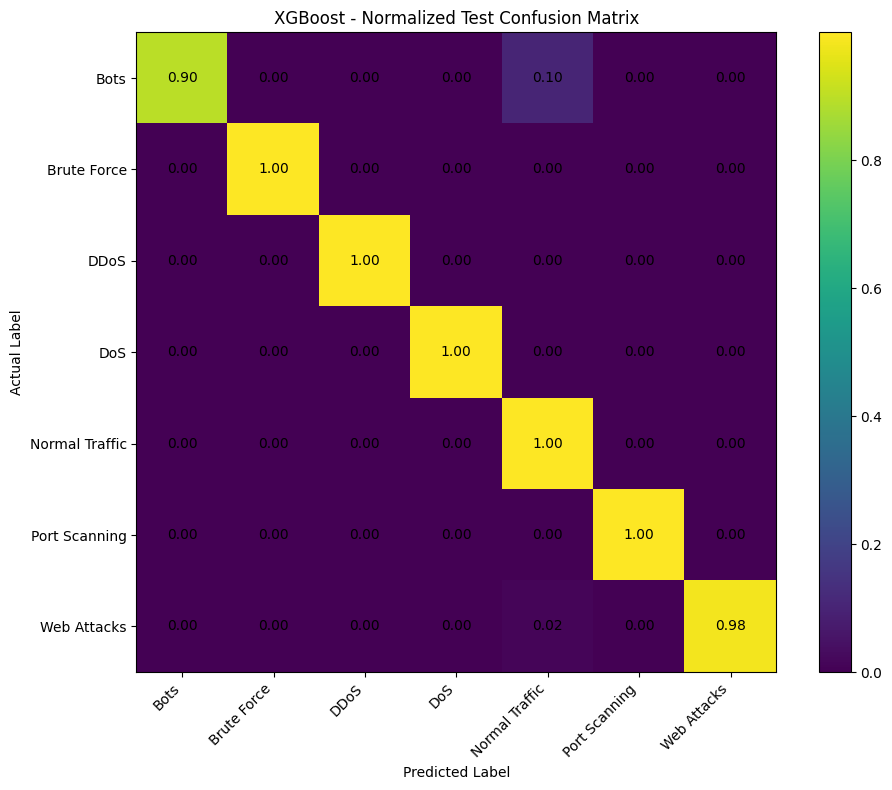

Normalized confusion matrix saved: /content/drive/MyDrive/Kalasag-models/xgboost_test_normalized_confusion_matrix.png


In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Normalize each row by its actual class total
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(10, 8))
plt.imshow(cm_normalized, interpolation='nearest')
plt.title('XGBoost - Normalized Test Confusion Matrix')
plt.colorbar()

class_names = [
    'Bots', 'Brute Force', 'DDoS', 'DoS',
    'Normal Traffic', 'Port Scanning', 'Web Attacks'
]

plt.xticks(range(7), class_names, rotation=45, ha='right')
plt.yticks(range(7), class_names)

for i in range(7):
    for j in range(7):
        plt.text(j, i, f'{cm_normalized[i, j]:.2f}',
                 ha='center', va='center')

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()

# Save to Google Drive
matrix_path = '/content/drive/MyDrive/Kalasag-models/xgboost_test_normalized_confusion_matrix.png'
plt.savefig(matrix_path, dpi=300, bbox_inches='tight')
plt.show()

print("Normalized confusion matrix saved:", matrix_path)

In [19]:
print("NORMALIZED CONFUSION MATRIX")
print("=" * 60)

for i, class_name in enumerate(class_names):
    print(f"\n{class_name}:")
    print(np.round(cm_normalized[i], 4))

NORMALIZED CONFUSION MATRIX

Bots:
[0.8973 0.     0.     0.     0.1027 0.     0.    ]

Brute Force:
[0.     0.9985 0.     0.     0.0015 0.     0.    ]

DDoS:
[0.000e+00 0.000e+00 9.996e-01 0.000e+00 4.000e-04 0.000e+00 0.000e+00]

DoS:
[0.000e+00 0.000e+00 0.000e+00 9.993e-01 5.000e-04 2.000e-04 0.000e+00]

Normal Traffic:
[4.00e-04 0.00e+00 0.00e+00 1.00e-04 9.99e-01 5.00e-04 0.00e+00]

Port Scanning:
[0.000e+00 0.000e+00 0.000e+00 1.000e-04 2.000e-04 9.995e-01 2.000e-04]

Web Attacks:
[0.     0.     0.     0.0031 0.0156 0.     0.9813]


In [20]:
import joblib

# Load a separate copy so the original final model stays unchanged
xgb_cpu = joblib.load(
    '/content/drive/MyDrive/Kalasag-models/xgboost.joblib'
)

# Configure this separate copy to use CPU
xgb_cpu.set_params(device='cpu')

print("Separate CPU model loaded successfully!")

Separate CPU model loaded successfully!


In [21]:
# Select one record from the existing test data
sample_record = X_test.iloc[[0]]

# Warm-up prediction (not part of final evaluation)
_ = xgb_cpu.predict(sample_record)

print("CPU warm-up completed successfully!")

CPU warm-up completed successfully!


In [22]:
import time
import numpy as np

times = []

for _ in range(100):
    start = time.perf_counter()
    _ = xgb_cpu.predict(sample_record)
    end = time.perf_counter()

    times.append((end - start) * 1000)

print("XGBoost CPU Inference Latency")
print("=" * 40)
print(f"Number of runs: {len(times)}")
print(f"Median latency: {np.median(times):.4f} ms")
print(f"Mean latency:   {np.mean(times):.4f} ms")
print(f"Minimum:        {np.min(times):.4f} ms")
print(f"Maximum:        {np.max(times):.4f} ms")

XGBoost CPU Inference Latency
Number of runs: 100
Median latency: 4.4272 ms
Mean latency:   5.2784 ms
Minimum:        2.5572 ms
Maximum:        28.2683 ms


In [23]:
import joblib
import os

final_model_path = '/content/drive/MyDrive/Kalasag-models/final_model.joblib'

# Save the approved XGBoost model
joblib.dump(xgb_final, final_model_path)

print("Final model saved successfully!")
print("Location:", final_model_path)
print("File exists:", os.path.exists(final_model_path))

Final model saved successfully!
Location: /content/drive/MyDrive/Kalasag-models/final_model.joblib
File exists: True


In [24]:
import joblib
import os

saved_model_path = '/content/drive/MyDrive/Kalasag-models/final_model.joblib'

verified_model = joblib.load(saved_model_path)

print("FINAL MODEL VERIFICATION")
print("=" * 40)
print("File exists:", os.path.exists(saved_model_path))
print("Model loaded:", verified_model is not None)
print("Model type:", type(verified_model).__name__)
print("Number of features:", verified_model.n_features_in_)

FINAL MODEL VERIFICATION
File exists: True
Model loaded: True
Model type: XGBClassifier
Number of features: 46


In [25]:
import pandas as pd
import os

results_folder = '/content/drive/MyDrive/Kalasag-models'

# Save raw confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)
cm_df.to_csv(
    f'{results_folder}/xgboost_test_confusion_matrix.csv'
)

# Save normalized confusion matrix
cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=class_names,
    columns=class_names
)
cm_normalized_df.to_csv(
    f'{results_folder}/xgboost_test_normalized_confusion_matrix.csv'
)

print("Test confusion matrix files saved!")
print(os.listdir(results_folder))

Test confusion matrix files saved!
['practice_tree.joblib', 'decision_tree.joblib', 'logistic_regression.joblib', 'random_forest.joblib', 'xgboost.joblib', 'xgboost_test_normalized_confusion_matrix.png', 'final_model.joblib', 'xgboost_test_confusion_matrix.csv', 'xgboost_test_normalized_confusion_matrix.csv']


In [26]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4, 5, 6],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_path = '/content/drive/MyDrive/Kalasag-models/xgboost_test_classification_report.csv'

report_df.to_csv(report_path)

print("Classification report saved!")
print("Location:", report_path)
print("File exists:", os.path.exists(report_path))

Classification report saved!
Location: /content/drive/MyDrive/Kalasag-models/xgboost_test_classification_report.csv
File exists: True


In [27]:
import os

folder = '/content/drive/MyDrive/Kalasag-models'

print("KALASAG MODEL HANDOFF CHECK")
print("=" * 45)

required_files = [
    'final_model.joblib',
    'xgboost_test_confusion_matrix.csv',
    'xgboost_test_normalized_confusion_matrix.csv',
    'xgboost_test_normalized_confusion_matrix.png',
    'xgboost_test_classification_report.csv'
]

for file in required_files:
    exists = os.path.exists(os.path.join(folder, file))
    print(f"{file}: {'READY' if exists else 'MISSING'}")

KALASAG MODEL HANDOFF CHECK
final_model.joblib: READY
xgboost_test_confusion_matrix.csv: READY
xgboost_test_normalized_confusion_matrix.csv: READY
xgboost_test_normalized_confusion_matrix.png: READY
xgboost_test_classification_report.csv: READY


In [28]:
import os

path = '/content/drive/MyDrive/kalasag/Kalasag-models/final_model.joblib'

print("Checking final model...")
print("File exists:", os.path.exists(path))

Checking final model...
File exists: True


In [29]:
import sys
import sklearn
import imblearn
import joblib
import xgboost

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("joblib:", joblib.__version__)
print("XGBoost:", xgboost.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
scikit-learn: 1.6.1
imbalanced-learn: 0.14.2
joblib: 1.6.0
XGBoost: 3.4.1


In [30]:
import joblib

scaler = joblib.load(f'{BASE}/scaler.pkl')

print("Scaler type:", type(scaler).__name__)
print("Number of features:", scaler.n_features_in_)

NameError: name 'BASE' is not defined

In [32]:
import joblib

scaler_path = '/content/drive/MyDrive/processed/scaler.pkl'
scaler = joblib.load(scaler_path)

print("Scaler type:", type(scaler).__name__)
print("Number of features:", scaler.n_features_in_)

Scaler type: StandardScaler
Number of features: 46


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [33]:
!pip install shap

In [34]:
print(type(xgb))
print("Features:", xgb.n_features_in_)
print("Validation features:", X_val.shape[1])

NameError: name 'xgb' is not defined

In [35]:
import os

print("Files in model folder:")
print(os.listdir(SAVE))

Files in model folder:


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Kalasag-models'

In [36]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'received_2303667026616590.mp4', '2021-05-28 01-43-57.mp4', '2021-06-07 15-22-14_Trim.mp4', '2021-06-07 19-04-08_Trim.mp4', '2021-12-21 14-52-30.mkv', 'ROBLOX MAMA MO.mp4', '2022-11-17 00-54-54 (1).mkv', 'ALI&MACDON_DRRR.mp4', 'Ali, Jasmine', 'okay.mp4', '2022-11-17 00-54-54.mkv', 'roblox', '25. PROGRAMMING CODING ULTIMATE COURSE', 'gta5 shot.mp4', 'KASAL NI JAZE AT TECO', 'KASAL NI LAI AT SATORU', 'KASAL NI ANTON AT REKO', 'ROBLOX', '2x2.jpg', 'CS1A-PathFit-Format (2).docx', 'CS1A-PathFit-Format (1).docx', 'CS1A-PathFit-Format.docx', 'Botb', '4ATIS_WEEKNO.1.gdoc', 'muwah - Made with Clipchamp.mp4', 'Reflexes - Made with Clipchamp.mp4', 'mowah.mp4', 'REPO CLIPS', 'forest', 'Screenshot 2025-07-08 004505 (1).png', 'Screenshot 2025-07-08 004933 (1).png', 'Screenshot 2025-07-08 004556 (1).png', 'Screenshot 2025-07-08 004943 (1).png', 'Screenshot 2025-07-08 004951 (1).png', 'Screenshot 2025-07-08 005043 (1).png', 'Screenshot 2025-07-08 005513 (1).png', 'Screenshot 2025-0

In [37]:
print(os.listdir('/content/drive/MyDrive/kalasag'))

['Kalasag-models', 'processed', 'cicids2017_cleaned.csv', 'cleaned.parquet', 'model_outputs']


In [38]:
SAVE = '/content/drive/MyDrive/kalasag/Kalasag-models'

print(os.listdir(SAVE))

['practice_tree.joblib', 'decision_tree.joblib', 'logistic_regression.joblib', 'random_forest.joblib', 'xgboost.joblib', 'xgboost_test_normalized_confusion_matrix.png', 'final_model.joblib', 'xgboost_test_confusion_matrix.csv', 'xgboost_test_normalized_confusion_matrix.csv', 'xgboost_test_classification_report.csv']


In [39]:
import joblib

final_model = joblib.load(f'{SAVE}/final_model.joblib')

print("Final model loaded successfully!")
print("Model type:", type(final_model))
print("Number of features:", final_model.n_features_in_)
print("Validation features:", X_val.shape[1])

Final model loaded successfully!
Model type: <class 'xgboost.sklearn.XGBClassifier'>
Number of features: 46


NameError: name 'X_val' is not defined

In [40]:
import pandas as pd

BASE = '/content/drive/MyDrive/kalasag/processed'

val = pd.read_parquet(f'{BASE}/val_scaled.parquet')

X_val = val.drop(columns='label').astype('float32')
y_val = val['label'].astype('int64')

print("Validation features:", X_val.shape[1])
print("Validation records:", X_val.shape[0])
print("Model features:", final_model.n_features_in_)

Validation features: 46
Validation records: 377652
Model features: 46


In [41]:
import shap

explainer = shap.TreeExplainer(final_model)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [42]:
# Use 500 validation records only
X_shap = X_val.sample(n=500, random_state=42)

print("Calculating SHAP values...")

shap_values = explainer.shap_values(X_shap)

print("SHAP calculation completed!")
print("Sample records:", X_shap.shape[0])
print("Features:", X_shap.shape[1])
print("SHAP output shape:", np.array(shap_values).shape)

Calculating SHAP values...
SHAP calculation completed!
Sample records: 500
Features: 46
SHAP output shape: (500, 46, 7)


TOP 15 SHAP FEATURES


,Feature,Mean Absolute SHAP Value
0,Destination Port,2.873783
42,Init_Win_bytes_forward,1.246348
45,min_seg_size_forward,0.976831
43,Init_Win_bytes_backward,0.647468
22,Fwd IAT Min,0.618400
35,Packet Length Std,0.606323
25,Bwd IAT Std,0.451499
20,Fwd IAT Std,0.450125
31,Bwd Packets/s,0.425260
11,Bwd Packet Length Std,0.392254


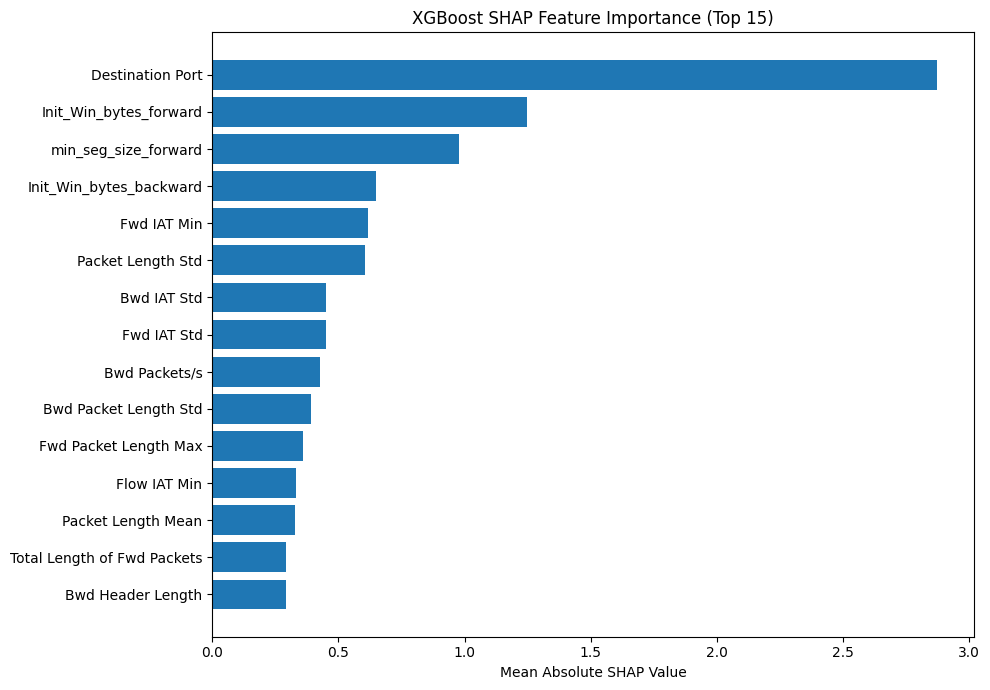

SHAP results saved successfully!


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate global SHAP importance across all 7 classes
mean_shap = np.abs(shap_values).mean(axis=(0, 2))

shap_importance = pd.DataFrame({
    'Feature': X_shap.columns,
    'Mean Absolute SHAP Value': mean_shap
})

shap_importance = shap_importance.sort_values(
    by='Mean Absolute SHAP Value',
    ascending=False
)

# Display top 15 features
print("TOP 15 SHAP FEATURES")
display(shap_importance.head(15))

# Save results
shap_importance.to_csv(
    f'{SAVE}/xgboost_shap_feature_importance.csv',
    index=False
)

# Create visualization
top15 = shap_importance.head(15).sort_values(
    'Mean Absolute SHAP Value'
)

plt.figure(figsize=(10, 7))
plt.barh(
    top15['Feature'],
    top15['Mean Absolute SHAP Value']
)
plt.xlabel('Mean Absolute SHAP Value')
plt.title('XGBoost SHAP Feature Importance (Top 15)')
plt.tight_layout()

plt.savefig(
    f'{SAVE}/xgboost_shap_feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("SHAP results saved successfully!")

In [44]:
import os

files = [
    'xgboost_shap_feature_importance.csv',
    'xgboost_shap_feature_importance.png'
]

for file in files:
    path = os.path.join(SAVE, file)
    print(file, "EXISTS" if os.path.exists(path) else "MISSING")

xgboost_shap_feature_importance.csv EXISTS
xgboost_shap_feature_importance.png EXISTS


In [45]:
mean_shap = np.abs(shap_values).mean(axis=(0, 2))